### Metadata
**Name**  
> Naveed Ahmad Hematmal

**Assignment**    

> Analytic Geometry

## 1: Compute L1, L2, Linf norms and cosine similarity for vectors: v1 = [1, -1, 2], v2 = [2, 0, -1].

In [1]:
import numpy as np

v1 = np.array([1, -1, 2])
v2 = np.array([2, 0, -1])

v1_l1 = np.linalg.norm(v1, ord=1)
v1_l2 = np.linalg.norm(v1, ord=2)
v1_linf = np.linalg.norm(v1, ord=np.inf)

print("L1 of v1:", v1_l1)
print("L2 of v1:", v1_l2)
print("L∞ of v1:", v1_linf)

v2_l1 = np.linalg.norm(v2, ord=1)
v2_l2 = np.linalg.norm(v2, ord=2)
v2_linf = np.linalg.norm(v2, ord=np.inf)

print("L1 of v2:", v2_l1)
print("L2 of v2:", v2_l2)
print("L∞ of v2:", v2_linf)

similarity = np.dot(v1, v2) / (
    np.linalg.norm(v1) * np.linalg.norm(v2)
)
print('cosine similarity of v1 and v2:', similarity)

L1 of v1: 4.0
L2 of v1: 2.449489742783178
L∞ of v1: 2.0
L1 of v2: 3.0
L2 of v2: 2.23606797749979
L∞ of v2: 2.0
cosine similarity of v1 and v2: 0.0


## 2: Implement Gram-Schmidt (or use above) on the matrix: M = [[1,2,3],[0,1,4],[5,6,0]] (columns as vectors). Check orthonormality of the result.

In [9]:
def gram_schmidt(A):
    Q = np.zeros_like(A)

    for i in range(A.shape[1]):
        v = A[:, i].copy()

        for j in range(i):
            v -= np.dot(v, Q[:, j]) * Q[:, j]

        Q[:, i] = v / np.linalg.norm(v)

    return Q

In [10]:
import numpy as np

M = np.array([
    [1, 2, 3],
    [0, 1, 4],
    [5, 6, 0]], dtype=float)

Q = gram_schmidt(M)

print("Orthonormal matrix:")
print(Q)

print("\nCheck Q.T @ Q:")
print(np.round(Q.T @ Q, 10))

Orthonormal matrix:
[[ 0.19611614  0.60522753 -0.77151675]
 [ 0.          0.78679579  0.6172134 ]
 [ 0.98058068 -0.12104551  0.15430335]]

Check Q.T @ Q:
[[ 1. -0.  0.]
 [-0.  1. -0.]
 [ 0. -0.  1.]]


## 3: Given A (design matrix) and b, compute least-squares solution and verify residual is orthogonal to column space of A.

In [11]:
import numpy as np

A = np.array([
    [1, 1],
    [1, 2],
    [1, 3]
], dtype=float)

b = np.array([1, 2, 2], dtype=float)

# Least-squares solution
x, *_ = np.linalg.lstsq(A, b, rcond=None)

# Predictions
y_pred = A @ x

# Residual
r = b - y_pred

# Orthogonality check
print("Solution:", x)
print("Residual:", r)
print("A.T @ r:", A.T @ r)

print("Orthogonal:",
      np.allclose(A.T @ r, 0))

Solution: [0.66666667 0.5       ]
Residual: [-0.16666667  0.33333333 -0.16666667]
A.T @ r: [-2.22044605e-16 -8.88178420e-16]
Orthogonal: True


## 4: Take functions f(x)=sin(2x), g(x)=sin(3x) on [0, 2π]. Numerically check orthogonality.

Inner product: 0.0
Orthogonal: True


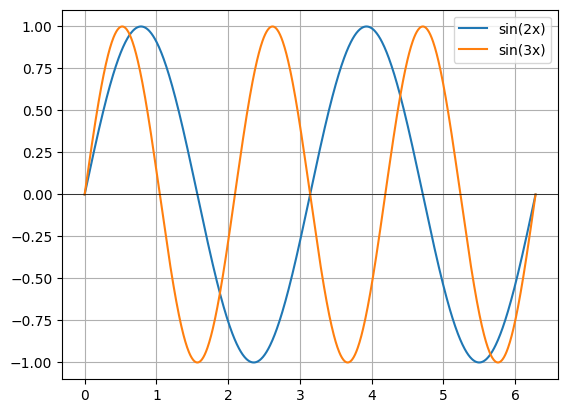

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Generate points
x = np.linspace(0, 2*np.pi, 1000)

# Define functions
f = np.sin(2*x)
g = np.sin(3*x)

# Compute numerical inner product
inner_product = np.trapezoid(f * g, x)

print("Inner product:", inner_product)

print("Orthogonal:",
      np.isclose(inner_product, 0))

# Plot both functions
plt.plot(x, f, label="sin(2x)")
plt.plot(x, g, label="sin(3x)")

plt.axhline(0, color="black", linewidth=0.5)
plt.legend()
plt.grid()
plt.show()

## 5: Rotate a set of 2D points by 45° and verify lengths preserved.

Original: [2.23606798 5.         7.81024968]
Rotated: [2.23606798 5.         7.81024968]
Preserved: True


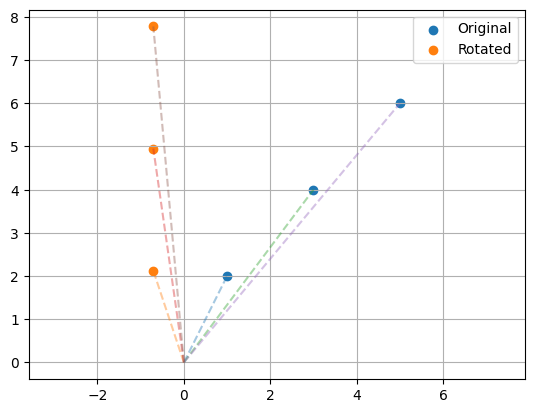

In [14]:
import numpy as np
import matplotlib.pyplot as plt

points = np.array([
    [1, 2],
    [3, 4],
    [5, 6]
])

# Rotation angle
angle = 45
theta = np.deg2rad(angle)

# Rotation matrix
R = np.array([
    [np.cos(theta), -np.sin(theta)],
    [np.sin(theta),  np.cos(theta)]
])

# Rotate points
rotated = points @ R.T

# Verify lengths
print("Original:", np.linalg.norm(points, axis=1))
print("Rotated:", np.linalg.norm(rotated, axis=1))
print("Preserved:", np.allclose(
    np.linalg.norm(points, axis=1),
    np.linalg.norm(rotated, axis=1)
))

# Visualize
plt.scatter(points[:, 0], points[:, 1], label="Original")
plt.scatter(rotated[:, 0], rotated[:, 1], label="Rotated")

for p, r in zip(points, rotated):
    plt.plot([0, p[0]], [0, p[1]], '--', alpha=0.4)
    plt.plot([0, r[0]], [0, r[1]], '--', alpha=0.4)

plt.axis("equal")
plt.grid()
plt.legend()
plt.show()